![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Ship Detection in the Strait of Hormuz with Sentinel-1

This capstone demonstrates two complementary GeoLattice workflows over the Hormuz Strait AOI: CFAR ship candidates from Sentinel-1 IW GRDH VV/VH imagery and, when matching local IW SLC data are available, range sub-look coherence at those candidates. The AOI and catalog records are stored in this notebook's `Data/08_remote_sensing/08_11_Capstones/hormuz_strait_sentinel1` directory.


## Overview

The Strait of Hormuz is a narrow, globally important maritime chokepoint linking the Persian Gulf with the Gulf of Oman. It carries energy as well as food and fertilizer trade, so disruption can affect supply chains well beyond the region. The [World Trade Organization's Strait of Hormuz portal](https://www.wto.org/english/res_e/statis_e/hormuz_global_trade_e.htm) documents trade impacts and measures connected with the 2026 Strait situation; its reporting includes measures introduced on or after February 28, 2026. Monitoring vessel presence after April 20 therefore provides useful situational context for observing traffic patterns during this wider period of disruption. The International Maritime Organization reported on 21 April that about 20,000 mariners and 2,000 ships were stranded in the Persian Gulf due to the closure.

Satellite ship-candidate detection can help analysts compare where vessels are visible across selected acquisition dates, identify areas for closer review, and complement maritime reports. Sentinel-1 SAR is useful because it can collect imagery at night and through cloud cover, but each image is only a snapshot, not continuous tracking. This notebook's April 23, 2026 acquisition is an example observation after April 20—not evidence that a specific incident occurred on that date. GRD detections are unverified radar candidates: they do not establish vessel identity, intent, threat, or route, and should be corroborated with AIS, trusted maritime notices such as [UKMTO](https://www.ukmto.org/), and independent image review.


## Scope and interpretation

The GRD search uses the requested 20–30 April 2026 interval and Planetary Computer's `sentinel-1-grd` collection. The catalog supplies georeferenced VV and VH measurement COGs plus calibration/noise XML assets; GeoLattice reads and calibrates only the AOI window. The notebook ranks matching acquisitions by their footprint overlap with the AOI and processes the best-overlapping IW dual-pol scene. A single granule may cover only part of this large AOI, so its coverage is reported and should not be mistaken for complete Strait coverage.

GRDH detections are bright point-like candidates relative to local sea clutter, not a vessel identification product. Coastlines, ports, islands, wakes, sidelobes, and azimuth ambiguities can all create false detections. No pre-CFAR speckle filter is applied because spatial filtering can smear small targets. Sub-look coherence is computed from complex SLC data and is a separate confirmation feature; GRD intensity cannot be used to calculate it. Planetary Computer does not publish an IW SLC collection, so the optional SLC section looks for matching SAFE products already present locally and explains when they are unavailable.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json
import re
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_gcps
from shapely.geometry import box, shape

from geolattice.rsense.sar import sentinel1, ship

plt.rcParams.update({"figure.dpi": 110})
DATA_DIR = Path("../../../../Data/08_remote_sensing/08_11_Capstones/hormuz_strait_sentinel1")
if not DATA_DIR.is_dir():
    DATA_DIR = Path("Data/08_remote_sensing/08_11_Capstones/hormuz_strait_sentinel1")
AOI_PATH = DATA_DIR / "AOI_hormuz_strait.geojson"
if not AOI_PATH.is_file():
    raise FileNotFoundError(f"Hormuz Strait AOI not found: {AOI_PATH.resolve()}")

aoi = gpd.read_file(AOI_PATH)
if aoi.empty:
    raise ValueError(f"AOI has no features: {AOI_PATH}")
if aoi.crs is None:
    aoi = aoi.set_crs("EPSG:4326")
aoi = aoi.to_crs("EPSG:4326")
aoi_geometry = aoi.geometry.union_all()
WEST, SOUTH, EAST, NORTH = aoi.total_bounds
BOUNDS = (WEST, SOUTH, EAST, NORTH)
# A bounded representative ship-lane window keeps full-resolution CFAR practical.
PROCESSING_BOUNDS = (56.15, 26.35, 56.65, 26.75)
processing_geometry = box(*PROCESSING_BOUNDS)
if not aoi_geometry.covers(processing_geometry):
    raise ValueError("PROCESSING_BOUNDS must lie inside the Hormuz Strait AOI")
print(f"GeoLattice Sentinel-1 ship workflow | AOI: {AOI_PATH}")
print(f"AOI bounds (west, south, east, north): {BOUNDS}")
print(f"Full-resolution processing bounds: {PROCESSING_BOUNDS}")
print(f"Local SAFE products: {len(list(DATA_DIR.rglob('*.SAFE')))}; "
      f"IW SLC products: {sum('_SLC__' in p.name for p in DATA_DIR.rglob('*.SAFE'))}")

GeoLattice Sentinel-1 ship workflow | AOI: data/hormuz_strait_sentinel1/AOI_hormuz_strait.geojson
AOI bounds (west, south, east, north): (np.float64(54.79212), np.float64(25.45471), np.float64(57.47066), np.float64(27.19471))
Full-resolution processing bounds: (56.15, 26.35, 56.65, 26.75)
Local SAFE products: 8; IW SLC products: 4


## AOI and acquisition search

The AOI GeoJSON stores coordinates in the required GeoJSON order, longitude then latitude. The STAC search filters to IW scenes with both VV and VH polarization. If matching local SLC SAFE products are present, the notebook first considers GRD scenes from the same platform and acquisition date so sub-look coherence can be demonstrated; it then selects the candidate with the largest projected AOI overlap. Otherwise, it selects the best-overlapping GRD scene. Full-resolution detection is bounded to `PROCESSING_BOUNDS`, a representative 0.5° by 0.4° ship-lane window inside the larger AOI, to control memory and run time. Change these bounds to investigate another part of the AOI. Repeat the processing for additional scene footprints to cover more area or build a date series.


Scenes with a same-platform/date local SLC: 4
Matching IW GRDH 1SDV scenes: 19
Selected: S1C_IW_GRDH_1SDV_20260423T021406_20260423T021435_007337_00EE1E
Acquisition: 2026-04-23T02:14:20.666965Z
Platform / relative orbit: sentinel-1c / 166
AOI area covered by this scene: 62.1%


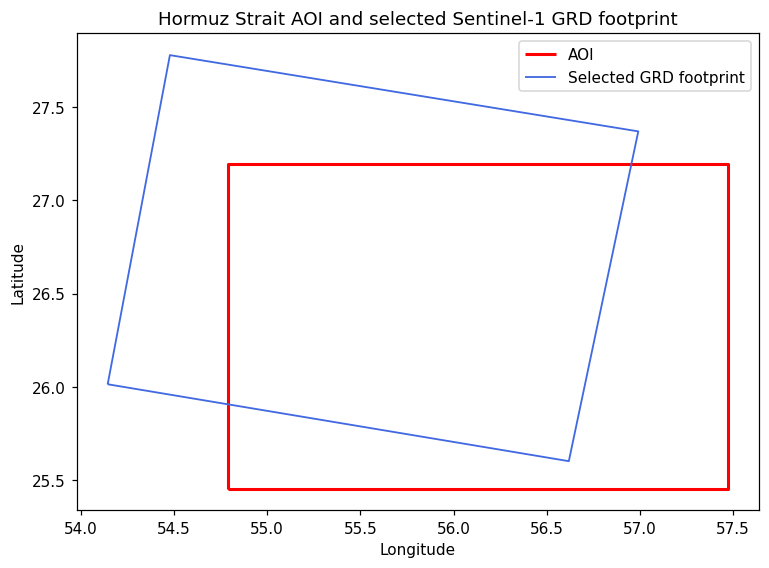

In [2]:
STAC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1/search"
SEARCH = {
    "collections": ["sentinel-1-grd"],
    "intersects": aoi_geometry.__geo_interface__,
    "datetime": "2026-04-20T00:00:00Z/2026-04-30T23:59:59Z",
    "limit": 100,
}
request = urllib.request.Request(
    STAC_URL,
    data=json.dumps(SEARCH).encode("utf-8"),
    headers={"Content-Type": "application/json", "Accept": "application/geo+json"},
    method="POST",
)
with urllib.request.urlopen(request, timeout=60) as response:
    search_result = json.load(response)
items = [
    item for item in search_result.get("features", [])
    if item.get("properties", {}).get("sar:instrument_mode") == "IW"
    and set(item.get("properties", {}).get("sar:polarizations", [])) == {"VV", "VH"}
    and "GRDH_1SDV" in item.get("id", "")
]
if not items:
    raise RuntimeError("Planetary Computer returned no IW GRDH 1SDV scenes for the AOI/date interval")

# Prefer acquisitions that can be paired with a local SLC; otherwise use any catalog match.
local_slc_keys = set()
for safe in DATA_DIR.rglob("*.SAFE"):
    if "_SLC__" not in safe.name:
        continue
    match = re.search(r"_(20\d{6})T", safe.name)
    if match:
        local_slc_keys.add((safe.name[:3], match.group(1)))
paired_items = [
    item for item in items
    if (item["id"][:3], item["properties"]["datetime"][:10].replace("-", "")) in local_slc_keys
]
candidate_items = paired_items if paired_items else items
print(f"Scenes with a same-platform/date local SLC: {len(paired_items)}")

# Rank by overlap area in a local projected CRS rather than by degree-squared area.
aoi_projected = aoi.to_crs("EPSG:32640")
aoi_area = float(aoi_projected.geometry.area.sum())
ranked_items = []
for item in candidate_items:
    footprint = gpd.GeoSeries([shape(item["geometry"])], crs="EPSG:4326").to_crs(aoi_projected.crs).iloc[0]
    overlap_area = float(footprint.intersection(aoi_projected.geometry.union_all()).area)
    ranked_items.append((overlap_area, item))
ranked_items.sort(key=lambda pair: pair[0], reverse=True)
overlap_area, selected_item = ranked_items[0]
coverage_fraction = overlap_area / aoi_area
selected_footprint = shape(selected_item["geometry"])
if not selected_footprint.intersects(processing_geometry):
    raise ValueError("Selected scene does not cover PROCESSING_BOUNDS; select another matching acquisition")

print(f"Matching IW GRDH 1SDV scenes: {len(items)}")
print(f"Selected: {selected_item['id']}")
print(f"Acquisition: {selected_item['properties']['datetime']}")
print(f"Platform / relative orbit: {selected_item['properties'].get('platform')} / "
      f"{selected_item['properties'].get('sat:relative_orbit')}")
print(f"AOI area covered by this scene: {coverage_fraction:.1%}")

# Keep an unsigned catalog record for provenance; never save the temporary access token.
record_path = DATA_DIR / "selected_grd_stac_item.json"
record_path.write_text(json.dumps(selected_item, indent=2) + "\n", encoding="utf-8")
footprint_gdf = gpd.GeoDataFrame(
    {"scene": [selected_item["id"]]},
    geometry=[shape(selected_item["geometry"])],
    crs="EPSG:4326",
)
fig, ax = plt.subplots(figsize=(8, 7))
aoi.boundary.plot(ax=ax, color="red", linewidth=2, label="AOI")
footprint_gdf.boundary.plot(ax=ax, color="royalblue", linewidth=1.2, label="Selected GRD footprint")
ax.set(title="Hormuz Strait AOI and selected Sentinel-1 GRD footprint", xlabel="Longitude", ylabel="Latitude")
ax.legend()
ax.set_aspect("equal")
plt.show()

## Read calibrated VV/VH over the AOI

Planetary Computer's Sentinel-1 GRD assets are cloud-optimized GeoTIFFs with ground control points. GeoLattice `read_grd_subset` uses these geolocation points together with the scene's calibration and noise XMLs to return linear sigma0 in the AOI window. Border-noise removal is limited to actual full-scene edges, not the artificial edges of the AOI crop. COG data are read remotely by window, so the full multi-hundred-megabyte measurement assets do not need to be downloaded first. A matching local COG, if present, is preferred; its calibration/noise metadata are still retrieved from the selected STAC item.


In [3]:
from geolattice.rsense.core.io import read_safe

local_grd_safes = sorted(
    safe for safe in DATA_DIR.rglob("*.SAFE")
    if "_GRDH_1SDV_" in safe.name and safe.name.startswith(selected_item["id"])
)
if local_grd_safes:
    safe_index = read_safe(local_grd_safes[0])
    vv_source, vh_source = safe_index["measurement"]["vv"], safe_index["measurement"]["vh"]
    vv_cal, vh_cal = safe_index["calibration"]["vv"], safe_index["calibration"]["vh"]
    vv_noise, vh_noise = safe_index["noise"]["vv"], safe_index["noise"]["vh"]
    print(f"Using local GRD SAFE: {local_grd_safes[0].name}")
else:
    token_url = "https://planetarycomputer.microsoft.com/api/sas/v1/token/sentinel-1-grd"
    with urllib.request.urlopen(token_url, timeout=30) as response:
        sas_token = json.load(response)["token"].lstrip("?")

    def signed_asset(key):
        href = selected_item["assets"][key]["href"]
        return href + ("&" if "?" in href else "?") + sas_token

    vv_source, vh_source = signed_asset("vv"), signed_asset("vh")
    vv_cal, vh_cal = signed_asset("schema-calibration-vv"), signed_asset("schema-calibration-vh")
    vv_noise, vh_noise = signed_asset("schema-noise-vv"), signed_asset("schema-noise-vh")
vv_result = sentinel1.read_grd_subset(
    vv_source,
    vv_cal,
    vv_noise,
    bounds=PROCESSING_BOUNDS,
    border_noise=True,
)
vh_result = sentinel1.read_grd_subset(
    vh_source,
    vh_cal,
    vh_noise,
    bounds=PROCESSING_BOUNDS,
    border_noise=True,
)
if vv_result["data"].shape != vh_result["data"].shape:
    raise ValueError("VV and VH AOI windows differ; check that both assets belong to the same GRD item")
vv = vv_result["data"]
vh = vh_result["data"]
gcps = vh_result["gcps"]
print(f"Calibrated AOI window: {vh.shape[0]:,} lines x {vh.shape[1]:,} samples")
print(f"Window in source scene: {vh_result['window']}")
print(f"Finite sigma0 pixels: VV={np.isfinite(vv).mean():.1%}, VH={np.isfinite(vh).mean():.1%}")
print("Sigma0 is in linear power; convert to dB only for display and contrast summaries.")

Using local GRD SAFE: S1C_IW_GRDH_1SDV_20260423T021406_20260423T021435_007337_00EE1E_C17A.SAFE


Calibrated AOI window: 5,284 lines x 5,772 samples
Window in source scene: (7234, 1266, 5284, 5772)
Finite sigma0 pixels: VV=100.0%, VH=100.0%
Sigma0 is in linear power; convert to dB only for display and contrast summaries.


## Mask land and build a sea-clutter field

A land/coastal exclusion mask prevents shoreline clutter from dominating CFAR. This cell caches Natural Earth's 1:10m land polygons in the AOI data folder, clips them to the AOI, and applies GeoLattice's configurable coastal buffer. Natural Earth is suitable for a regional demonstration but may omit small islands, port structures, and newly built features; inspect and improve the mask for operational use.


In [4]:
LAND_PATH = DATA_DIR / "ne_10m_land.geojson"
LAND_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_land.geojson"
if not LAND_PATH.exists():
    urllib.request.urlretrieve(LAND_URL, LAND_PATH)
land = gpd.read_file(LAND_PATH).to_crs("EPSG:4326")
land_geoms = [
    geom.intersection(processing_geometry)
    for geom in land.geometry
    if geom is not None and geom.intersects(processing_geometry)
]

window_transform = from_gcps(gcps)
inside_aoi = geometry_mask(
    [processing_geometry], out_shape=vh.shape, transform=window_transform, invert=True
)
land_mask = ship.land_mask_for_window(
    gcps,
    vh.shape,
    land_geoms,
    buffer_m=300.0,
    pixel_spacing=10.0,
)
sea = inside_aoi & ~land_mask & np.isfinite(vv) & np.isfinite(vh) & (vh > 0)
if not sea.any():
    raise ValueError("No valid sea pixels remain; inspect AOI overlap and coastline masking")
print(f"AOI sea pixels retained: {sea.sum():,} ({sea.mean():.1%} of the read window)")
print("Land mask includes a 300 m shoreline buffer to suppress coast and harbor clutter.")

AOI sea pixels retained: 21,557,730 (70.7% of the read window)
Land mask includes a 300 m shoreline buffer to suppress coast and harbor clutter.


## Detect GRD ship candidates with GeoLattice CFAR

GeoLattice `ship.cfar_tiled` evaluates a local background ring in unfiltered VH sigma0. This workflow estimates ENL from the most homogeneous valid sea blocks instead of assuming one nominal value for the whole scene. It also uses a more conservative pixel false-alarm threshold, requires adequate background support, and filters components by mean-power contrast (less sensitive to a single bright speckle pixel than peak contrast). These are screening candidates, not confirmed ships: GRD speckle, sea state, sidelobes, and bright structures can still cause false alarms, while conservative thresholds can miss small or low-contrast vessels. Lower `MIN_MEAN_CONTRAST_DB` to increase sensitivity after visual review.


In [5]:
PFA = 1e-8
ENL = ship.estimate_enl(vh, sea, block=64, max_cv_quantile=0.2)
OUTER_PIXELS = 101
GUARD_PIXELS = 61
MIN_MEAN_CONTRAST_DB = 12.0
vh_linear = np.nan_to_num(vh, nan=0.0, posinf=0.0, neginf=0.0)
detections, background_db = ship.cfar_tiled(
    vh_linear,
    sea,
    tile=1024,
    method="gamma",
    pfa=PFA,
    enl=ENL,
    outer=OUTER_PIXELS,
    guard=GUARD_PIXELS,
    min_ring_fraction=0.7,
)
targets = ship.extract_targets(
    detections,
    vh_linear,
    np.nan_to_num(vv, nan=0.0, posinf=0.0, neginf=0.0),
    gcps=gcps,
    background_db=background_db,
    pixel_spacing=10.0,
    min_px=3,
    max_px=500,
    min_mean_contrast_db=MIN_MEAN_CONTRAST_DB,
)
print(f"CFAR parameters: Pfa={PFA:g}, ENL={ENL:g}, guard={GUARD_PIXELS} px, outer={OUTER_PIXELS} px")
print(f"CFAR-positive pixels: {detections.sum():,}")
print(f"Candidates with mean contrast >= {MIN_MEAN_CONTRAST_DB:g} dB: {len(targets):,}")
targets = targets.sort_values("mean_contrast_db", ascending=False).reset_index(drop=True)
targets.head(20)

CFAR parameters: Pfa=1e-08, ENL=0.416509, guard=61 px, outer=101 px
CFAR-positive pixels: 1,452
Candidates with mean contrast >= 12 dB: 26


,row,col,n_px,vh_peak_db,vh_mean_db,length_m,width_m,orientation_deg,vv_peak_db,vh_vv_ratio_db,contrast_db,mean_contrast_db,lon,lat
0,4091.869344,3118.936384,126,1.102334,-7.110578,273.253493,67.348377,3.336058,6.732034,-5.911092,34.060704,25.847792,56.350623,26.422547
1,3153.831270,1394.879054,262,-6.281814,-12.460521,299.069228,123.649438,174.300539,1.952282,-7.685946,28.492028,22.313321,56.538516,26.477868
2,4963.227853,3754.201725,25,-9.514607,-12.532400,78.579687,46.011477,21.833890,-4.890213,-4.187628,24.664630,21.646837,56.271369,26.354765
3,2953.571297,1528.856784,210,-6.754776,-13.512618,317.639143,114.719477,109.505976,3.490391,-9.167010,28.248016,21.490174,56.529191,26.498180
4,4037.559680,1643.452359,405,-0.614313,-7.379700,301.922394,272.844478,4.718172,6.544401,-5.981623,27.848276,21.082889,56.496950,26.402483
5,2922.967540,1694.462701,141,-4.651999,-9.610602,228.082023,111.847911,132.145393,3.073403,-8.134205,24.704790,19.746187,56.513466,26.503745
6,4006.308757,2616.058801,7,-11.850231,-13.533391,38.284271,36.186147,90.000000,-9.561193,-0.018329,20.733925,19.050765,56.401790,26.421765
7,4954.066656,3754.447044,6,-13.810903,-15.339140,40.983867,28.973666,0.000000,-15.233375,1.256913,20.436233,18.907996,56.271520,26.355594
8,4337.441018,1145.185375,42,0.272990,-2.988762,145.816197,48.499140,16.592400,7.968748,-6.722213,21.694525,18.432773,56.540193,26.367010
9,4509.869254,1444.119147,41,-5.680630,-9.667087,130.644241,67.459137,21.620020,5.336879,-11.297613,22.345945,18.359488,56.507441,26.356556


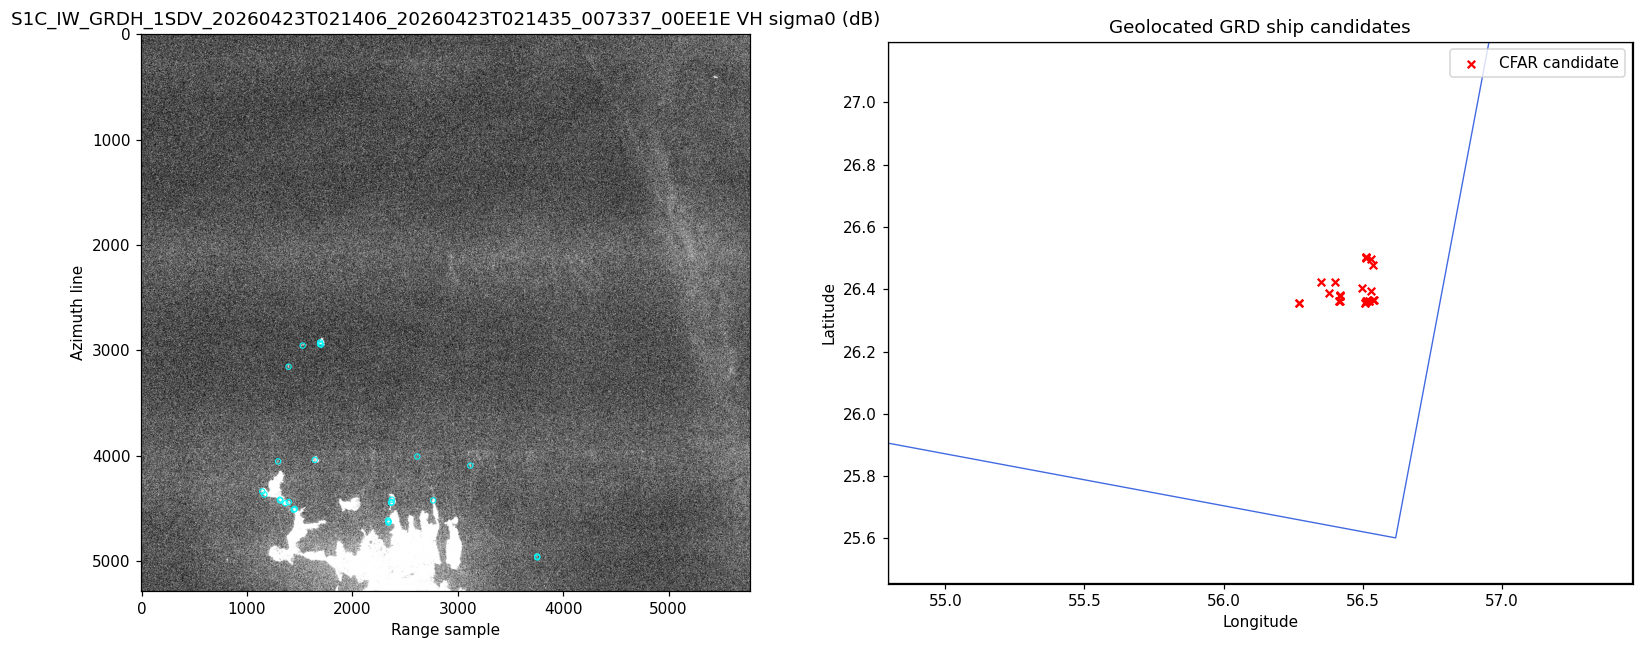

Saved candidate table: data/hormuz_strait_sentinel1/grd_ship_candidates.csv


In [6]:
vh_db = sentinel1.to_db(vh)
finite_db = vh_db[np.isfinite(vh_db) & sea]
if finite_db.size == 0:
    raise ValueError("No finite VH dB values inside the sea mask")
vmin, vmax = np.percentile(finite_db, [2, 98])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].imshow(vh_db, cmap="gray", vmin=vmin, vmax=vmax, origin="upper")
axes[0].set(title=f"{selected_item['id']} VH sigma0 (dB)", xlabel="Range sample", ylabel="Azimuth line")
axes[0].imshow(np.ma.masked_where(~detections, detections), cmap="autumn", alpha=0.35, origin="upper")
if not targets.empty:
    axes[0].scatter(targets.col, targets.row, s=12, facecolors="none", edgecolors="cyan", linewidths=0.7)

aoi.boundary.plot(ax=axes[1], color="black", linewidth=1.5)
footprint_gdf.boundary.plot(ax=axes[1], color="royalblue", linewidth=0.9)
if not targets.empty:
    axes[1].scatter(targets.lon, targets.lat, s=24, marker="x", color="red", label="CFAR candidate")
axes[1].set(xlim=(WEST, EAST), ylim=(SOUTH, NORTH), xlabel="Longitude", ylabel="Latitude",
            title="Geolocated GRD ship candidates")
axes[1].legend(loc="best")
plt.tight_layout()
plt.show()

target_path = DATA_DIR / "grd_ship_candidates.csv"
targets.to_csv(target_path, index=False)
print(f"Saved candidate table: {target_path}")

The GRD catalog item supplies measurement, calibration, and noise assets, but not the original IW annotation needed by GeoLattice to read the pulse repetition frequency and build the incidence-angle grid for azimuth-ambiguity tests. Therefore this remote-COG path does not automatically label ambiguity ghosts. If the matching original GRD SAFE is available locally, use `ship.detect_ships_grd` (or `ship.read_prf`, `sentinel1.incidence_angle_grid`, and `ship.flag_azimuth_ambiguities`) to add that quality-control step. Candidate tables should be reviewed against imagery and, where possible, independent vessel reports.


## Optional IW SLC range sub-look coherence

Range sub-looks split an IW SLC's processed range spectrum into lower- and upper-frequency images; GeoLattice calculates their local coherence with `ship.sublook_coherence`. Ships often retain higher coherence between sub-looks than sea clutter. Use an SLC from the same platform, pass, relative orbit, and acquisition as the GRD candidates where possible. This is not coherence between two dates or a replacement for interferometric coherence.

Planetary Computer publishes GRD and RTC collections, not SLC. Place an authorized, matching IW SLC SAFE product in `Data/08_remote_sensing/08_11_Capstones/hormuz_strait_sentinel1` to run the optional cell below. The processing is limited to IW1 and bursts whose range window intersects the AOI; select IW2/IW3 as appropriate for other swath coverage.


In [7]:
SLC_SWATH = "IW1"
slc_safes = sorted(DATA_DIR.rglob("*.SAFE"))
slc_matches = [
    safe for safe in slc_safes
    if "_SLC__" in safe.name and safe.name[:3] == selected_item["id"][:3]
    and selected_item["properties"]["datetime"][:10].replace("-", "") in safe.name
]
if not slc_matches:
    print("No same-platform, same-date IW SLC SAFE found locally.")
    print("Planetary Computer's Sentinel-1 collection does not provide SLC; range sub-look coherence was not computed.")
    print("Add a matching authorized SAFE with annotation/ and measurement/ folders, then rerun this cell.")
else:
    import pandas as pd

    slc_safe = slc_matches[0]
    annotation_path = next(iter(sorted(slc_safe.glob(f"annotation/*-{SLC_SWATH.lower()}-slc-vv-*.xml"))), None)
    measurement_path = next(iter(sorted(slc_safe.glob(f"measurement/*-{SLC_SWATH.lower()}-slc-vv-*.tiff"))), None)
    if annotation_path is None or measurement_path is None:
        raise FileNotFoundError(f"Could not find {SLC_SWATH} VV annotation and measurement in {slc_safe}")
    ann = sentinel1.read_slc_annotation(annotation_path)
    processing_params = ship.read_processing_params(annotation_path)
    if targets.empty:
        print("No GRD candidates are available to sample for SLC sub-look coherence.")
    else:
        # Process a small neighborhood around the strongest GRD candidate to bound SLC memory.
        target_index = targets["mean_contrast_db"].idxmax() if "mean_contrast_db" in targets else targets.index[0]
        target = targets.loc[target_index]
        delta_lon = 0.015
        delta_lat = 0.015
        target_bounds = (
            max(PROCESSING_BOUNDS[0], float(target.lon) - delta_lon),
            max(PROCESSING_BOUNDS[1], float(target.lat) - delta_lat),
            min(PROCESSING_BOUNDS[2], float(target.lon) + delta_lon),
            min(PROCESSING_BOUNDS[3], float(target.lat) + delta_lat),
        )
        burst_ids, burst_cols = [], []
        for burst_id in range(len(ann["bursts"])):
            cols = sentinel1.burst_window(ann, burst_id, target_bounds, margin=200)
            if cols[1] - cols[0] >= 64:
                burst_ids.append(burst_id)
                burst_cols.append(cols)
        if not burst_ids:
            raise ValueError(f"No {SLC_SWATH} SLC bursts cover the strongest GRD candidate")
        common_cols = (min(c[0] for c in burst_cols), max(c[1] for c in burst_cols))
        coherence_layers = []
        for burst_id in burst_ids:
            burst = sentinel1.read_slc_burst(measurement_path, ann, burst_id, cols=common_cols)
            lower, upper = ship.range_sublooks(burst, processing_params, ann["range_sampling_rate"])
            valid_burst = np.isfinite(burst) & (np.abs(burst) > 0)
            coherence, _ = ship.sublook_coherence(lower, upper, window=(3, 9), valid=valid_burst)
            coherence_layers.append(coherence)
        candidate_coherence = ship.coherence_at_points(
            [target.lat], [target.lon], ann, burst_ids, common_cols, coherence_layers, sea_height=0.0
        )[0]
        targets.loc[target_index, "slc_range_sublook_coherence"] = candidate_coherence
        targets.to_csv(target_path, index=False)
        print(f"Strongest candidate index: {target_index} | sub-look coherence: {candidate_coherence:.3f}")
        print(f"Processed {len(burst_ids)} {SLC_SWATH} burst(s) around a bounded candidate window.")
        print(f"Updated candidate table: {target_path}")
    print(f"SLC source: {slc_safe.name} | swath: {SLC_SWATH}")

Strongest candidate index: 0 | sub-look coherence: 0.358
Processed 11 IW1 burst(s) around a bounded candidate window.
Updated candidate table: data/hormuz_strait_sentinel1/grd_ship_candidates.csv
SLC source: S1C_IW_SLC__1SDV_20260423T021406_20260423T021436_007337_00EE1E_7D39.SAFE | swath: IW1


## View candidate detections on satellite imagery

This interactive Leafmap view overlays the AOI, the full-resolution processing window, and the screened GRD candidate locations on Esri World Imagery. Click a marker to inspect its backscatter, contrast, size, and optional SLC coherence. Satellite tiles require an internet connection. These points are candidate detections, not confirmed vessel identities.


In [8]:
import leafmap

map_center = ((PROCESSING_BOUNDS[1] + PROCESSING_BOUNDS[3]) / 2,
              (PROCESSING_BOUNDS[0] + PROCESSING_BOUNDS[2]) / 2)
ship_map = leafmap.Map(
    center=map_center,
    zoom=9,
    height="700px",
    draw_control=False,
    measure_control=False,
)
ship_map.add_basemap("Esri.WorldImagery")
for layer in list(ship_map.layers):
    if getattr(layer, "name", None) == "OpenStreetMap":
        ship_map.remove_layer(layer)

ship_map.add_gdf(
    aoi,
    layer_name="Hormuz Strait AOI",
    style={"color": "#00ffff", "weight": 2, "fill": False},
    zoom_to_layer=False,
)
processing_area = gpd.GeoDataFrame(
    {"name": ["Full-resolution processing window"]},
    geometry=[processing_geometry],
    crs="EPSG:4326",
)
ship_map.add_gdf(
    processing_area,
    layer_name="Processing window",
    style={"color": "#ff9900", "weight": 3, "fill": False},
    zoom_to_layer=False,
)

if not targets.empty:
    popup_fields = [
        field for field in [
            "mean_contrast_db", "contrast_db", "vh_peak_db", "vh_mean_db",
            "vh_vv_ratio_db", "n_px", "length_m", "width_m",
            "slc_range_sublook_coherence",
        ]
        if field in targets.columns
    ]
    ship_map.add_points_from_xy(
        targets,
        x="lon",
        y="lat",
        popup=popup_fields,
        layer_name="GRD ship candidates",
        marker_colors=["red"],
        icon_colors=["white"],
        icon_names=["info"],
        add_legend=False,
    )
    print(f"Mapped {len(targets):,} screened candidate locations.")
else:
    print("No candidates passed the current screening thresholds; showing the AOI and processing window.")

ship_map.add_layer_control()
ship_map

Mapped 26 screened candidate locations.


Map(center=[26.55, 56.4], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_ou…

## Repeat the analysis near Abu Musa

This second run uses the user-provided southwest and northeast coordinates (SW 26.483593, 54.904882; NE 25.877560, 55.953254), normalized to `(west, south, east, north)` order. It reuses the selected Sentinel-1 acquisition and the same calibration, shoreline mask, adaptive ENL estimate, and CFAR thresholds, then saves a separate candidate table and maps the results on satellite imagery. The selected scene intersects this region; its footprint covers approximately 99.96% of the requested rectangle, so check the footprint and image edges when interpreting detections.


In [9]:
ABUMUSA_BOUNDS = (54.904882, 25.877560, 55.953254, 26.483593)
abumusa_geometry = box(*ABUMUSA_BOUNDS)
if not aoi_geometry.covers(abumusa_geometry):
    raise ValueError("The Abu Musa analysis bounds must lie inside the Hormuz Strait AOI")
if not selected_footprint.intersects(abumusa_geometry):
    raise ValueError("The selected GRD scene does not intersect the Abu Musa analysis bounds")

vv_abumusa_result = sentinel1.read_grd_subset(
    vv_source, vv_cal, vv_noise, bounds=ABUMUSA_BOUNDS, border_noise=True
)
vh_abumusa_result = sentinel1.read_grd_subset(
    vh_source, vh_cal, vh_noise, bounds=ABUMUSA_BOUNDS, border_noise=True
)
if vv_abumusa_result["data"].shape != vh_abumusa_result["data"].shape:
    raise ValueError("VV and VH Abu Musa windows differ; check that assets belong to the same GRD item")
vv_abumusa = vv_abumusa_result["data"]
vh_abumusa = vh_abumusa_result["data"]
gcps_abumusa = vh_abumusa_result["gcps"]

land_geoms_abumusa = [
    geom.intersection(abumusa_geometry)
    for geom in land.geometry
    if geom is not None and geom.intersects(abumusa_geometry)
]
inside_abumusa = geometry_mask(
    [abumusa_geometry],
    out_shape=vh_abumusa.shape,
    transform=from_gcps(gcps_abumusa),
    invert=True,
)
land_mask_abumusa = ship.land_mask_for_window(
    gcps_abumusa,
    vh_abumusa.shape,
    land_geoms_abumusa,
    buffer_m=300.0,
    pixel_spacing=10.0,
)
sea_abumusa = (
    inside_abumusa & ~land_mask_abumusa
    & np.isfinite(vv_abumusa) & np.isfinite(vh_abumusa) & (vh_abumusa > 0)
)
if not sea_abumusa.any():
    raise ValueError("No valid sea pixels remain in the Abu Musa analysis window")

enl_abumusa = ship.estimate_enl(vh_abumusa, sea_abumusa, block=64, max_cv_quantile=0.2)
detections_abumusa, background_db_abumusa = ship.cfar_tiled(
    np.nan_to_num(vh_abumusa, nan=0.0, posinf=0.0, neginf=0.0),
    sea_abumusa,
    tile=1024,
    method="gamma",
    pfa=PFA,
    enl=enl_abumusa,
    outer=OUTER_PIXELS,
    guard=GUARD_PIXELS,
    min_ring_fraction=0.7,
)
targets_abumusa = ship.extract_targets(
    detections_abumusa,
    np.nan_to_num(vh_abumusa, nan=0.0, posinf=0.0, neginf=0.0),
    np.nan_to_num(vv_abumusa, nan=0.0, posinf=0.0, neginf=0.0),
    gcps=gcps_abumusa,
    background_db=background_db_abumusa,
    pixel_spacing=10.0,
    min_px=3,
    max_px=500,
    min_mean_contrast_db=MIN_MEAN_CONTRAST_DB,
)
targets_abumusa = targets_abumusa.sort_values(
    "mean_contrast_db", ascending=False
).reset_index(drop=True)
print(f"Abu Musa bounds (west, south, east, north): {ABUMUSA_BOUNDS}")
print(f"Calibrated window: {vh_abumusa.shape[0]:,} x {vh_abumusa.shape[1]:,} pixels")
print(f"Valid sea pixels: {sea_abumusa.sum():,} | estimated ENL: {enl_abumusa:.3f}")
print(f"CFAR-positive pixels: {detections_abumusa.sum():,}")
print(f"Candidates with mean contrast >= {MIN_MEAN_CONTRAST_DB:g} dB: {len(targets_abumusa):,}")
targets_abumusa.head(20)

Abu Musa bounds (west, south, east, north): (54.904882, 25.87756, 55.953254, 26.483593)
Calibrated window: 8,287 x 11,535 pixels
Valid sea pixels: 69,039,381 | estimated ENL: 0.391
CFAR-positive pixels: 16,160
Candidates with mean contrast >= 12 dB: 118


,row,col,n_px,vh_peak_db,vh_mean_db,length_m,width_m,orientation_deg,vv_peak_db,vh_vv_ratio_db,contrast_db,mean_contrast_db,lon,lat
0,3665.280509,4997.196243,241,6.881856,-2.905714,252.062701,128.655179,96.079123,20.256527,-13.189842,43.454946,33.667376,55.517631,26.220959
1,5967.186315,3530.963893,274,11.353215,-1.232927,244.961864,132.756816,145.541492,15.859336,-2.742412,46.243794,33.657652,55.618506,25.989697
2,6521.524003,6083.012781,336,9.020777,-3.137752,320.685897,131.007447,10.677860,17.350533,-8.711006,45.603327,33.444798,55.357656,25.981599
3,3795.043131,1539.876312,250,15.770464,0.063228,301.887115,167.583572,81.940667,28.983803,-13.264128,49.058676,33.351440,55.855042,26.152350
4,6756.887886,2782.897183,160,7.123175,-2.414209,202.341411,105.202706,12.660142,23.917654,-13.808729,42.676020,33.138636,55.676857,25.906294
5,5995.467146,2259.854096,293,9.402098,-0.294708,324.937521,111.040613,173.628646,20.845428,-10.848326,42.582937,32.886131,55.742570,25.966189
6,7176.586548,5088.914343,276,8.372971,-2.357689,285.626770,127.164938,165.046032,13.932909,-6.471220,43.287121,32.556461,55.442957,25.906408
7,6390.453500,2158.751955,152,9.621654,-1.668342,203.995084,100.583173,170.115520,17.132710,-9.165892,43.842406,32.552410,55.744952,25.928966
8,5128.160474,1689.317992,149,6.927065,-2.028878,200.250502,96.727144,167.868472,14.233139,-8.522249,41.368769,32.412825,55.815001,26.034819
9,7208.760111,5503.855922,176,8.917558,-2.905909,220.451272,106.253128,174.731769,19.228285,-10.776181,43.808846,31.985379,55.401661,25.910297


If a matching local IW SLC was found above, the next cell searches IW1, IW2, and IW3 for the swath that covers the strongest Abu Musa candidate and samples its range sub-look coherence. The coherence value is supplemental; it is not a standalone ship classifier.


In [10]:
if targets_abumusa.empty:
    print("No Abu Musa candidates are available for the optional SLC coherence sample.")
elif not slc_matches:
    print("No matching local IW SLC is available; Abu Musa candidates remain GRD-only.")
else:
    target_abumusa = targets_abumusa.iloc[0]
    target_bounds_abumusa = (
        max(ABUMUSA_BOUNDS[0], float(target_abumusa.lon) - 0.015),
        max(ABUMUSA_BOUNDS[1], float(target_abumusa.lat) - 0.015),
        min(ABUMUSA_BOUNDS[2], float(target_abumusa.lon) + 0.015),
        min(ABUMUSA_BOUNDS[3], float(target_abumusa.lat) + 0.015),
    )
    swath_match = None
    for swath in ("IW1", "IW2", "IW3"):
        annotation_candidate = next(
            iter(sorted(slc_safe.glob(f"annotation/*-{swath.lower()}-slc-vv-*.xml"))), None
        )
        if annotation_candidate is None:
            continue
        annotation_candidate_data = sentinel1.read_slc_annotation(annotation_candidate)
        burst_candidate_ids, burst_candidate_cols = [], []
        for burst_id in range(len(annotation_candidate_data["bursts"])):
            cols = sentinel1.burst_window(
                annotation_candidate_data, burst_id, target_bounds_abumusa, margin=200
            )
            if cols[1] - cols[0] >= 64:
                burst_candidate_ids.append(burst_id)
                burst_candidate_cols.append(cols)
        if burst_candidate_ids:
            swath_match = (
                swath, annotation_candidate, annotation_candidate_data,
                burst_candidate_ids, burst_candidate_cols,
            )
            break

    if swath_match is None:
        print("No IW swath bursts cover the strongest Abu Musa candidate; coherence was skipped.")
    else:
        (swath_abumusa, annotation_path_abumusa, ann_abumusa,
         burst_ids_abumusa, burst_cols_abumusa) = swath_match
        measurement_path_abumusa = next(
            iter(sorted(slc_safe.glob(
                f"measurement/*-{swath_abumusa.lower()}-slc-vv-*.tiff"
            ))), None
        )
        if measurement_path_abumusa is None:
            raise FileNotFoundError(
                f"Could not find {swath_abumusa} VV SLC measurement in {slc_safe}"
            )
        processing_params_abumusa = ship.read_processing_params(annotation_path_abumusa)
        common_cols_abumusa = (
            min(cols[0] for cols in burst_cols_abumusa),
            max(cols[1] for cols in burst_cols_abumusa),
        )
        coherence_layers_abumusa = []
        for burst_id in burst_ids_abumusa:
            burst = sentinel1.read_slc_burst(
                measurement_path_abumusa, ann_abumusa, burst_id, cols=common_cols_abumusa
            )
            lower, upper = ship.range_sublooks(
                burst, processing_params_abumusa, ann_abumusa["range_sampling_rate"]
            )
            valid_burst = np.isfinite(burst) & (np.abs(burst) > 0)
            coherence_layer, _ = ship.sublook_coherence(
                lower, upper, window=(3, 9), valid=valid_burst
            )
            coherence_layers_abumusa.append(coherence_layer)
        coherence_abumusa = ship.coherence_at_points(
            [target_abumusa.lat], [target_abumusa.lon], ann_abumusa,
            burst_ids_abumusa, common_cols_abumusa, coherence_layers_abumusa, sea_height=0.0
        )[0]
        targets_abumusa.loc[0, "slc_range_sublook_coherence"] = coherence_abumusa
        print(
            f"Strongest Abu Musa candidate mean contrast: {target_abumusa.mean_contrast_db:.2f} dB | "
            f"{swath_abumusa} range sub-look coherence: {coherence_abumusa:.3f}"
        )

Strongest Abu Musa candidate mean contrast: 33.67 dB | IW2 range sub-look coherence: 0.346


### Abu Musa candidate map

Candidate markers are clickable for their GRD measurements and, when computed, the strongest candidate’s optional SLC coherence. The CSV is kept separate from the first processing window.


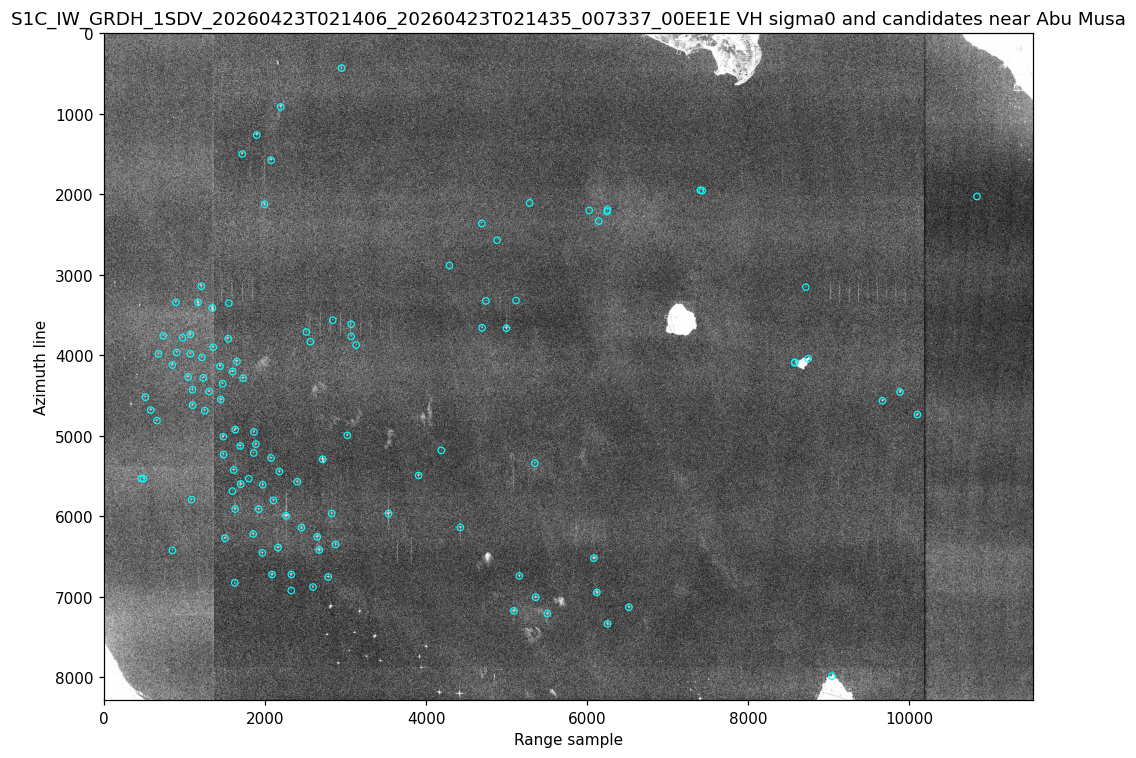

Saved Abu Musa candidate table: data/hormuz_strait_sentinel1/grd_ship_candidates_abu_musa.csv


Mapped 118 Abu Musa candidate locations.


Map(center=[26.1805765, 55.429068], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title'…

In [11]:
abumusa_csv_path = DATA_DIR / "grd_ship_candidates_abu_musa.csv"
targets_abumusa.to_csv(abumusa_csv_path, index=False)

vh_abumusa_db = sentinel1.to_db(vh_abumusa)
finite_abumusa_db = vh_abumusa_db[np.isfinite(vh_abumusa_db) & sea_abumusa]
if finite_abumusa_db.size == 0:
    raise ValueError("No finite VH dB values inside the Abu Musa sea mask")
vmin_abumusa, vmax_abumusa = np.percentile(finite_abumusa_db, [2, 98])
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(vh_abumusa_db, cmap="gray", vmin=vmin_abumusa, vmax=vmax_abumusa, origin="upper")
ax.imshow(
    np.ma.masked_where(~detections_abumusa, detections_abumusa),
    cmap="autumn", alpha=0.35, origin="upper",
)
if not targets_abumusa.empty:
    ax.scatter(
        targets_abumusa.col, targets_abumusa.row,
        s=18, facecolors="none", edgecolors="cyan", linewidths=0.8,
    )
ax.set(
    title=f"{selected_item['id']} VH sigma0 and candidates near Abu Musa",
    xlabel="Range sample", ylabel="Azimuth line",
)
plt.tight_layout()
plt.show()
print(f"Saved Abu Musa candidate table: {abumusa_csv_path}")

abumusa_map = leafmap.Map(
    center=((ABUMUSA_BOUNDS[1] + ABUMUSA_BOUNDS[3]) / 2,
            (ABUMUSA_BOUNDS[0] + ABUMUSA_BOUNDS[2]) / 2),
    zoom=9,
    height="700px",
    draw_control=False,
    measure_control=False,
)
abumusa_map.add_basemap("Esri.WorldImagery")
for layer in list(abumusa_map.layers):
    if getattr(layer, "name", None) == "OpenStreetMap":
        abumusa_map.remove_layer(layer)
abumusa_map.add_gdf(
    aoi,
    layer_name="Hormuz Strait AOI",
    style={"color": "#00ffff", "weight": 2, "fill": False},
    zoom_to_layer=False,
)
abumusa_area = gpd.GeoDataFrame(
    {"name": ["Abu Musa analysis bounds"]},
    geometry=[abumusa_geometry],
    crs="EPSG:4326",
)
abumusa_map.add_gdf(
    abumusa_area,
    layer_name="Abu Musa analysis window",
    style={"color": "#ff9900", "weight": 3, "fill": False},
    zoom_to_layer=False,
)
if not targets_abumusa.empty:
    popup_fields_abumusa = [
        field for field in [
            "mean_contrast_db", "contrast_db", "vh_peak_db", "vh_mean_db",
            "vh_vv_ratio_db", "n_px", "length_m", "width_m",
            "slc_range_sublook_coherence",
        ]
        if field in targets_abumusa.columns
    ]
    abumusa_map.add_points_from_xy(
        targets_abumusa,
        x="lon",
        y="lat",
        popup=popup_fields_abumusa,
        layer_name="Abu Musa GRD candidates",
        marker_colors=["red"],
        icon_colors=["white"],
        icon_names=["info"],
        add_legend=False,
    )
    print(f"Mapped {len(targets_abumusa):,} Abu Musa candidate locations.")
else:
    print("No candidates passed the current screening thresholds.")
abumusa_map.add_layer_control()
abumusa_map

## Review, validation, and limitations

The candidate CSV is an initial detection list. Inspect candidates near coastlines, ports, islands, and bright fixed structures; compare VV/VH contrast and size; and check for along-track ghost patterns. If AIS data are available for this region and acquisition time, GeoLattice `ship.match_points` can compare detections with vessel positions and `ship.detection_scores` can report precision, recall, and F1. AIS is not bundled here and should only be used after verifying its timestamp, coverage, and position accuracy. Do not treat unvalidated detections or coherence thresholds as confirmed vessel identities.


## Summary and conclusions

This notebook uses GeoLattice to search Sentinel-1 IW GRDH dual-polarization acquisitions, read a georeferenced AOI window with radiometric calibration and noise removal, mask land and coastal clutter, and find candidate vessels using tiled gamma-CFAR on VH intensity. It reports the selected scene's AOI coverage and saves candidate attributes to CSV. If a matching local IW SLC SAFE is supplied, range sub-look coherence can be sampled at the GRD candidates as an additional feature. The candidate locations are also displayed interactively on satellite imagery with Leafmap. A second analysis and satellite map cover the user-provided Abu Musa area, with a separate candidate CSV.

The catalog's GRD data are not complex SLC samples, so they cannot support sub-look coherence by themselves. This example selects one scene rather than mosaicking the full multi-orbit catalog. Scene-edge coverage, coastline quality, false alarms, ambiguities, and vessel motion must be reviewed before operational use; independent AIS or manual image interpretation is recommended for validation.


## Additional resources

- [Microsoft Planetary Computer Sentinel-1 GRD collection](https://planetarycomputer.microsoft.com/dataset/sentinel-1-grd)
- [Sentinel-1 mission and product documentation](https://sentinels.copernicus.eu/web/sentinel/user-guides/sentinel-1-sar)
- [GeoLattice Sentinel-1 processing module](../../../../src/rsense/sar/sentinel1.py)
- [GeoLattice ship detection and sub-look coherence module](../../../../src/rsense/sar/ship.py)
- [Natural Earth land data](https://www.naturalearthdata.com/)

The Planetary Computer token is held only in memory during the notebook session and is not written to the catalog record. Access to SLC products must be obtained separately from a provider that distributes complex IW SLC data.
